# Training a pixel regressor

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Training a U-Net to predict NDVI from Sentinel-2 bands, with settings you can change and compare
</div>
<!-- markdownlint-enable MD033 -->

---

On the previous page, the 2018 Beni scene was cut into 100 tile pairs and split by location into 70 training and 20 validation tiles. This page trains a regression model on them. All important choices are collected in one settings cell, so you can change them, re-run the page, and see which decisions matter.

---

## 1. Motivation

This is the page where the architecture and loss-function decisions from page 3 become a trained model. `geoai` hides most of the implementation behind a handful of parameters; your job is to understand what each one controls well enough to make good choices for your own data, and to read the training curves well enough to know whether the result can be trusted.

---

## 2. Core idea

`geoai.train_pixel_regressor()` builds the model, the data loaders and the training loop in a single call. It uses the AdamW optimizer, halves the learning rate when the validation loss has not improved for 5 epochs, stops early when it has not improved for `patience` epochs, and returns the {term}`checkpoint <Checkpoint>` with the lowest validation loss.

The most interesting setting on this page is `BANDS`. With all six bands, the model has red and NIR available and "only" needs to learn the NDVI formula. Without NIR, the formula is impossible, and the model has to estimate NDVI from what visible colours and spatial patterns reveal about vegetation.

```{admonition} Training takes a few minutes
:class: note
With the default settings, training takes 3–7 minutes on an Apple M3 laptop (Apple GPU) and should be faster on a {term}`CUDA` {term}`GPU`. On a CPU-only machine, expect 30–60 minutes; reduce `MAX_EPOCHS` to 30 for a first try. The outputs on this page come from one such run; your numbers will differ slightly.
```

---

## 3. Workflow

### A. Imports and experiment settings

In [1]:
import json
import logging
import os
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
for name in ["lightning.pytorch", "lightning.fabric", "rasterio"]:
    logging.getLogger(name).setLevel(logging.ERROR)

import geoai
import lightning as L
import pandas as pd
import torch

The next cell is the only one you need to edit. Run the page once with the defaults, then change **one** setting at a time and re-run everything below it, so you know which change caused a difference.

In [2]:
# ============================ EXPERIMENT SETTINGS ============================
BANDS = "all"  # "all": blue, green, red, NIR, SWIR1, SWIR2 (6 bands)
               # "rgb": blue, green, red only (3 bands, no NIR)
               # "no_nir": all except NIR (5 bands)
ARCHITECTURE = "unet"  # "unet", "unetplusplus", "deeplabv3plus", "fpn", ...
ENCODER = "resnet34"  # "resnet18", "resnet34", "resnet50", ...
LOSS = "mse"  # "mse", "l1" or "huber" (see page 3)
LEARNING_RATE = 1e-3
BATCH_SIZE = 8
MAX_EPOCHS = 100
PATIENCE = 20  # stop when the validation loss has not improved for this many epochs
SEED = 0  # change it to see how much results vary between runs
# ==============================================================================

BAND_SETS = {"all": [1, 2, 3, 4, 5, 6], "rgb": [1, 2, 3], "no_nir": [1, 2, 3, 5, 6]}
input_bands = BAND_SETS[BANDS]
in_channels = len(input_bands)

EXPERIMENT = f"{ARCHITECTURE}-{ENCODER}_{BANDS}_{LOSS}_lr{LEARNING_RATE:g}_seed{SEED}"
RUN_DIR = Path("regression_runs") / EXPERIMENT
L.seed_everything(SEED, workers=True)
print("Experiment:", EXPERIMENT, f"({in_channels} input bands)")

Experiment: unet-resnet34_all_mse_lr0.001_seed0 (6 input bands)


`input_bands` lists the bands (counted from 1, as in `rasterio`) that are read from each tile. Because the tiles from page 4 contain all six bands, changing `BANDS` needs no new tiles. `in_channels` is derived from that list rather than typed by hand, so the model always matches its input.

| Setting | Default | What it controls |
| --- | --- | --- |
| `BANDS` | `"all"` | Which spectral information the model receives |
| `ARCHITECTURE`, `ENCODER` | `"unet"`, `"resnet34"` | The encoder-decoder network (page 3) |
| `LOSS` | `"mse"` | How errors are penalized (page 3) |
| `LEARNING_RATE`, `BATCH_SIZE` | `1e-3`, `8` | Step size and number of tiles per update |
| `MAX_EPOCHS`, `PATIENCE` | `100`, `20` | Maximum training length and {term}`early stopping <Early Stopping>` |
| `SEED` | `0` | The {term}`random seed <Random Seed>`: initial weights and tile order |

### B. Load the tile split from page 4

In [3]:
split_file = Path("regression_tiles/beni_2018/split.json")
if not split_file.exists():
    raise FileNotFoundError("Run the previous page first: it downloads the data and creates the tiles.")
split = json.loads(split_file.read_text())
train_imgs, train_tgts = map(list, zip(*split["train"]))
val_imgs, val_tgts = map(list, zip(*split["val"]))
print(f"Training tiles: {len(train_imgs)}, validation tiles: {len(val_imgs)}")

Training tiles: 70, validation tiles: 20


### C. Train the model

In [4]:
start = time.time()
model = geoai.train_pixel_regressor(
    train_image_paths=train_imgs,
    train_target_paths=train_tgts,
    val_image_paths=val_imgs,
    val_target_paths=val_tgts,
    input_bands=input_bands,
    in_channels=in_channels,
    architecture=ARCHITECTURE,
    encoder_name=ENCODER,
    encoder_weights="imagenet",
    output_dir=str(RUN_DIR),
    batch_size=BATCH_SIZE,
    num_epochs=MAX_EPOCHS,
    learning_rate=LEARNING_RATE,
    loss_type=LOSS,
    patience=PATIENCE,
    verbose=False,
)
fit_minutes = (time.time() - start) / 60
print(f"Training took {fit_minutes:.1f} minutes")
print("Best checkpoint:", Path(model.best_model_path).name)

Training took 3.1 minutes
Best checkpoint: resnet34_unet_epoch=82_val_loss=0.0021.ckpt


`encoder_weights="imagenet"` starts the encoder from weights learned on ImageNet photographs, the same {term}`transfer learning <Transfer Learning>` idea as in L05 and L07. ImageNet images have three channels, so what happens with six? The first layer of the encoder is rebuilt for six inputs, and the pretrained RGB filters are reused in turn (band 1 gets the filters of the red channel, band 2 those of green, band 3 those of blue, band 4 those of red again, and so on), scaled down so that the total input strength stays the same. That is a reasonable starting point, not a meaningful one for NIR or SWIR; training adapts these filters to the actual bands.

`verbose=False` keeps the output short: a single progress bar summarises each epoch. The checkpoint file name contains the epoch and validation loss of the best model, which is the one returned and used below.

### D. Read the training curves

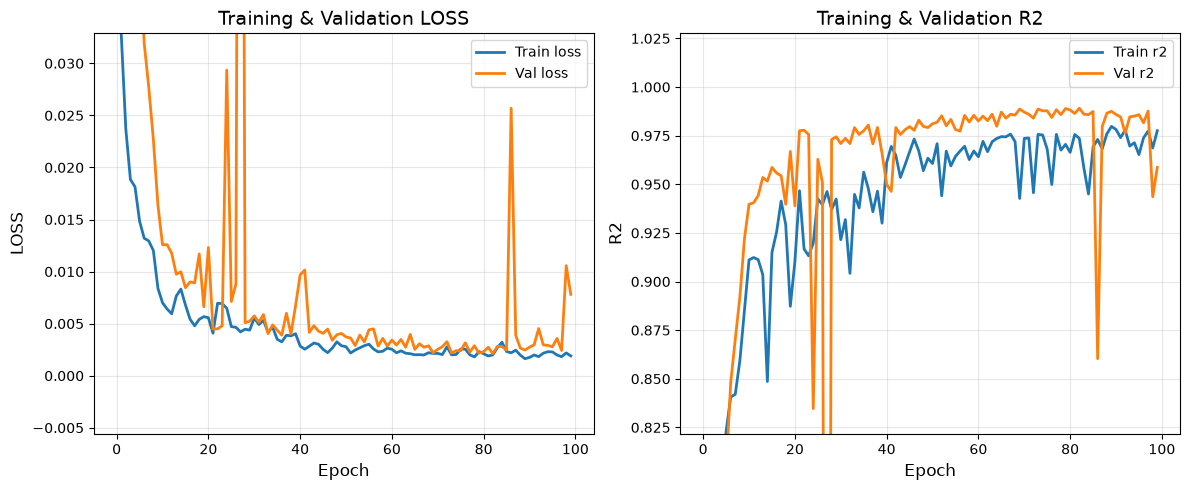

In [5]:
fig, history = geoai.plot_training_history(log_dir=str(RUN_DIR), metrics=["loss", "r2"])

The left panel shows the loss ({term}`mean squared error <Mean Squared Error>` here), the right panel {term}`R² <R-squared>`, both for training and validation. Three things to look for:

- **Both curves fall (loss) or rise (R²) together.** This is a healthy run. If training loss kept falling while validation loss rose, the model would be {term}`overfitting <Overfitting>`: learning the training tiles rather than the relationship.
- **The validation curve is jumpy.** With only 20 validation tiles, a few difficult tiles (river edges, sand bars) move the average. Look at the trend, not at single epochs.
- **Training R² can be lower than validation R².** That is not an error. Training values are averaged over the epoch while the model is still changing, and computed per batch of 8 tiles; validation values are computed once, with the model at the end of the epoch. Compare trends, not absolute values.

`plot_training_history()` zooms in automatically when the first epochs are far off the scale (here the first validation loss is above 8, because the untrained model outputs arbitrary values).

### E. The best epoch, and how the result compares

In [6]:
best_epoch = int(history["val_loss"].idxmin())
best = history.loc[best_epoch]
print(f"Epochs trained: {len(history)}, best epoch: {best_epoch}")
print(f"Validation at the best epoch: RMSE {best['val_rmse']:.3f} NDVI, "
      f"MAE {best['val_mae']:.3f} NDVI, R² {best['val_r2']:.3f}")

results_file = Path("regression_runs/results.csv")
row = pd.DataFrame([{
    "experiment": EXPERIMENT, "bands": BANDS, "loss": LOSS, "seed": SEED,
    "epochs": len(history), "best_epoch": best_epoch, "minutes": round(fit_minutes, 1),
    "val_rmse": round(best["val_rmse"], 4), "val_mae": round(best["val_mae"], 4),
    "val_r2": round(best["val_r2"], 4),
}])
if results_file.exists():
    old = pd.read_csv(results_file)
    row = pd.concat([old[old["experiment"] != EXPERIMENT], row], ignore_index=True)
row.to_csv(results_file, index=False)
row

Epochs trained: 100, best epoch: 82
Validation at the best epoch: RMSE 0.046 NDVI, MAE 0.026 NDVI, R² 0.989


,experiment,bands,loss,seed,epochs,best_epoch,minutes,val_rmse,val_mae,val_r2
0,unet-resnet34_all_mse_lr0.001_seed0,all,mse,0,100,82,3.1,0.0458,0.0258,0.9891


The table in `results.csv` grows by one row for every experiment you run (a repeated experiment replaces its old row). It is your lab notebook: after a few runs it shows which settings actually changed the validation scores, and by how much.

Validation {term}`RMSE <Root Mean Squared Error>` and {term}`MAE <Mean Absolute Error>` are in NDVI units: the model's predictions for the held-out southern area are typically off by a few hundredths. Page 7 looks at where these errors occur.

```{admonition} What changing the settings did in our runs
:class: tip
We ran the page with different settings on an Apple M3 laptop. Validation scores are for the southern held-out area of 2018 at the best epoch; the last column anticipates page 7 and gives the error for the same area in 2026, the year the model never saw.

| Settings | Epochs | Validation RMSE | Validation R² | RMSE south, 2026 |
| --- | --- | --- | --- | --- |
| `BANDS="all"`, `LOSS="mse"`, seed 0 (default) | 100 | 0.046 | 0.989 | 0.059 |
| `BANDS="all"`, seed 1 | 87 | 0.050 | 0.987 | 0.079 |
| `BANDS="all"`, `LOSS="l1"` | 73 | 0.075 | 0.972 | 0.095 |
| `BANDS="no_nir"` (5 bands) | 100 | 0.055 | 0.985 | 0.081 |
| `BANDS="rgb"` (3 bands) | 90 | 0.088 | 0.960 | 0.146 |
| `BANDS="rgb"`, seed 1 | 68 | 0.122 | 0.924 | 0.161 |

- **The bands matter most.** With red, green and blue only, the validation error roughly doubles, and in the new year it is two to three times larger than with all bands: a relationship learned from colours transfers less well to another date than one built on NIR.
- **Removing only NIR costs less than expected.** The SWIR bands also separate vegetation from water and bare soil. The difference to the all-band model is about as large as the difference between two seeds of the same settings.
- **Seeds matter.** The same settings with another seed changed the 2026 error from 0.059 to 0.079. Differences smaller than this are not evidence that one setting is better.
- **MAE (`"l1"`) did worse** on this clean, computed target and stopped early. As page 3 suggested, MSE suits targets without outliers.
```

### F. Save what the next pages need

In [7]:
latest = {
    "experiment": EXPERIMENT,
    "checkpoint": os.path.relpath(model.best_model_path),
    "input_bands": input_bands,
}
Path("regression_runs/latest.json").write_text(json.dumps(latest, indent=1))
print(json.dumps(latest, indent=1))

{
 "experiment": "unet-resnet34_all_mse_lr0.001_seed0",
 "checkpoint": "regression_runs/unet-resnet34_all_mse_lr0.001_seed0/models/resnet34_unet_epoch=82_val_loss=0.0021.ckpt",
 "input_bands": [
  1,
  2,
  3,
  4,
  5,
  6
 ]
}


The next page loads the model from this checkpoint, so it can run without training again. If you train several experiments, `latest.json` always points to the most recent one.

---

## 4. Python reactivation

`train_pixel_regressor()` is called entirely with keyword arguments, the self-documenting pattern used for training functions throughout this course. Two small patterns from this page are useful beyond regression:

- `map(list, zip(*pairs))` turns a list of pairs `[(img1, tgt1), (img2, tgt2), ...]` into two lists `[img1, img2, ...]` and `[tgt1, tgt2, ...]`; `zip(*...)` "unzips" the pairs.
- `pd.concat([old[old["experiment"] != EXPERIMENT], row])` keeps all old rows except the one being replaced, then appends the new row: a simple way to keep one row per experiment in a results table.

---

## 5. Common pitfalls

- **Hardcoding `in_channels` instead of deriving it from the bands used.** If you change the bands but not `in_channels`, training fails with a shape error, or, worse, a model is trained for the wrong input.
- **Changing several settings at once.** Then you cannot tell which change caused a difference; change one setting per run and record the result.
- **Over-interpreting a difference smaller than the variation between seeds.** Re-run the default with another `SEED` to see how much scores vary by chance.
- **Reading single epochs of a jumpy validation curve.** With few validation tiles, look at the trend and at the best epoch, not at individual values.
- **Setting `patience` too low.** Training may stop at a temporary plateau, before the learning-rate reduction has had a chance to help.

---

## 6. Mini task

1. Set `BANDS = "rgb"` and re-run the page from step A. How much do validation RMSE and R² change compared with the default?
2. The model still reaches a fairly high R² without the NIR band. What information in red, green and blue images allows it to estimate NDVI at all? Where would you expect it to fail?

:::{dropdown} Sample solution
:class: note

1. In our runs, the validation RMSE rose from 0.046 to 0.088 and R² fell from 0.989 to 0.960 (a second seed gave 0.122 and 0.924). The exact values vary between runs, but the loss is far larger than the variation between seeds of the all-band model. The effect is even stronger in the new year (page 7): 0.146 instead of 0.059 for the southern area in 2026.

2. NDVI is high for dense green vegetation and low for water, sand and bare soil. These surfaces also differ in visible colour and texture: forest is dark green and rough, water is dark and smooth or turquoise and sediment-laden, sand bars are bright, savanna is lighter and greener-brown. A CNN also sees spatial context: a pixel in the middle of a river is water, a pixel inside a forest canopy is vegetation. What it cannot see without NIR is how *vigorous* the vegetation is: two canopies of similar colour can have quite different NIR reflectance. Expect the largest errors where vegetation types of similar colour have different NDVI (savanna versus degraded forest), and at mixed pixels along river banks and sand bars.
:::

---

## 7. Key takeaways

- `train_pixel_regressor()` handles model construction, data loading and the training loop, and returns the checkpoint with the lowest validation loss.
- `input_bands` selects bands from existing tiles; derive `in_channels` from it instead of typing it.
- ImageNet weights are adapted to more than three bands by reusing the RGB filters in turn; training then adapts them.
- Read loss and R² curves together, judge trends rather than single epochs, and keep a results table so experiments stay comparable.
- With all bands, the model reproduces NDVI with errors of a few hundredths; with red, green and blue only it still captures the broad pattern, but with errors two to three times larger, especially in a new year.
- Re-run with another seed before trusting a small difference between settings.

### Further reading

- OpenGeoAI, ["Train timm Regressor"](https://opengeoai.org/examples/train_timm_regressor/) — the `geoai` example notebook this workflow is based on.
- [segmentation_models_pytorch on GitHub](https://github.com/qubvel-org/segmentation_models.pytorch), section "Input channels" — how pretrained encoders are adapted to a different number of input bands.